# Patient data exploration

Student engineering project output — not real clinical guidance. This notebook profiles the supplied dataset, visualizes its distributions and compares the saved classifiers.

In [1]:
from pathlib import Path
import sys
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root) not in sys.path: sys.path.insert(0, str(root))
from src.common import DATA, OUTPUT, read_json
from IPython.display import display, Image, Markdown


In [2]:
from src.data_pipeline import load_records
df = load_records()
print('Shape:', df.shape)
display(df.dtypes.to_frame('Data type'))
display(df.head())
display(df.describe(include='all'))
display(df.isna().sum().to_frame('Missing cells'))

Shape: (500, 7)


,Data type
Patient_ID,str
Age,int64
Biomarker_Level,float64
Pre_Existing_Conditions,int64
Vaccine_Dose_mcg,float64
Prior_Reaction_History,str
Reaction_Score,int64


,Patient_ID,Age,Biomarker_Level,Pre_Existing_Conditions,Vaccine_Dose_mcg,Prior_Reaction_History,Reaction_Score
0,P0001,24,4.53,1,83.5,Mild,1
1,P0002,70,1.65,1,46.2,None,0
2,P0003,62,1.92,1,124.6,None,1
3,P0004,47,12.48,1,57.6,None,1
4,P0005,47,2.11,1,44.2,Mild,0


,Patient_ID,Age,Biomarker_Level,Pre_Existing_Conditions,Vaccine_Dose_mcg,Prior_Reaction_History,Reaction_Score
count,500,500.000000,480.000000,500.000000,500.000000,483,500.000000
unique,500,NaN,NaN,NaN,NaN,3,NaN
top,P0001,NaN,NaN,NaN,NaN,None,NaN
freq,1,NaN,NaN,NaN,NaN,291,NaN
mean,NaN,51.444000,5.283438,1.262000,86.552400,NaN,0.490000
std,NaN,19.444976,2.841475,1.195078,36.232862,NaN,0.500401
min,NaN,18.000000,0.640000,0.000000,25.100000,NaN,0.000000
25%,NaN,35.000000,3.175000,0.000000,56.775000,NaN,0.000000
50%,NaN,51.000000,4.820000,1.000000,84.550000,NaN,0.000000
75%,NaN,68.250000,6.952500,2.000000,118.675000,NaN,1.000000


,Missing cells
Patient_ID,0
Age,0
Biomarker_Level,20
Pre_Existing_Conditions,0
Vaccine_Dose_mcg,0
Prior_Reaction_History,17
Reaction_Score,0


## Cleaning and leakage prevention

The string `None` is a valid reaction-history category. Only blank cells are missing. The 80/20 stratified split uses seed 42, and preprocessing is fitted on training rows only. Patient ID is excluded from predictors.

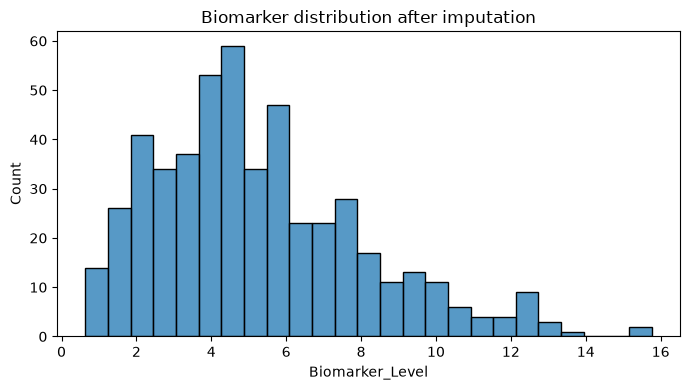

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from src.data_pipeline import clean_records
train, test = train_test_split(df, test_size=.2, stratify=df.Reaction_Score, random_state=42)
clean = clean_records(df, train)
assert not clean.isna().any().any()
fig, ax = plt.subplots(figsize=(7,4))
sns.histplot(clean.Biomarker_Level, bins=25, ax=ax)
ax.set_title('Biomarker distribution after imputation')
plt.tight_layout(); plt.show()

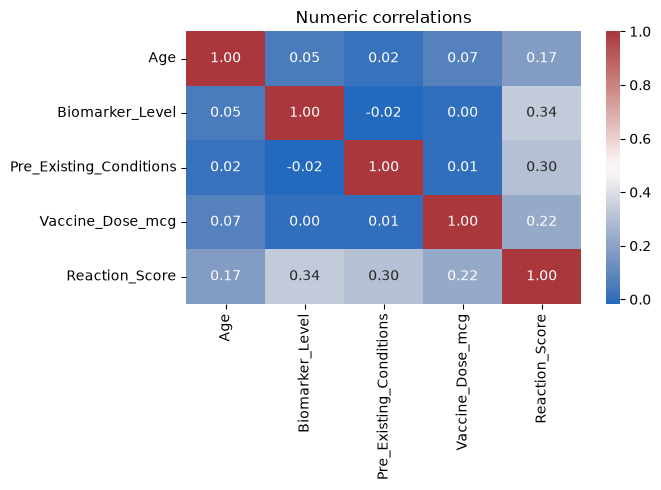

In [4]:
fig, ax = plt.subplots(figsize=(7,5))
columns = ['Age', 'Biomarker_Level', 'Pre_Existing_Conditions', 'Vaccine_Dose_mcg', 'Reaction_Score']
sns.heatmap(clean[columns].corr(), annot=True, fmt='.2f', cmap='vlag', ax=ax)
ax.set_title('Numeric correlations')
plt.tight_layout(); plt.show()

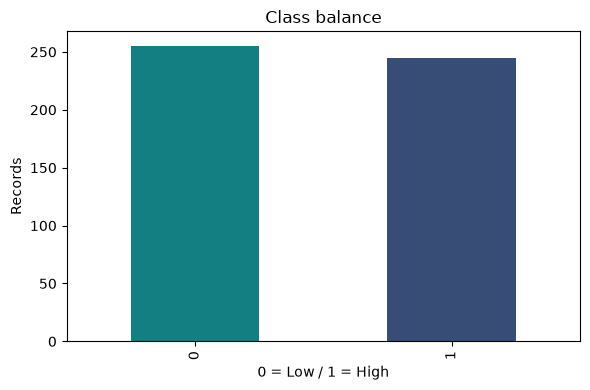

In [5]:
fig, ax = plt.subplots(figsize=(6,4))
df.Reaction_Score.value_counts().sort_index().plot.bar(ax=ax, color=['#137f83','#384d76'])
ax.set(title='Class balance', xlabel='0 = Low / 1 = High', ylabel='Records')
plt.tight_layout(); plt.show()

## Classifier comparison

Both models use identical training data. Positive-class F1 selects the winner, as specified by the PRD. Using the test set for selection means an independent holdout would be needed for an unbiased final estimate.

,F1,AUC
logistic_regression,0.702128,0.767907
random_forest,0.646465,0.714086


Selected: logistic_regression


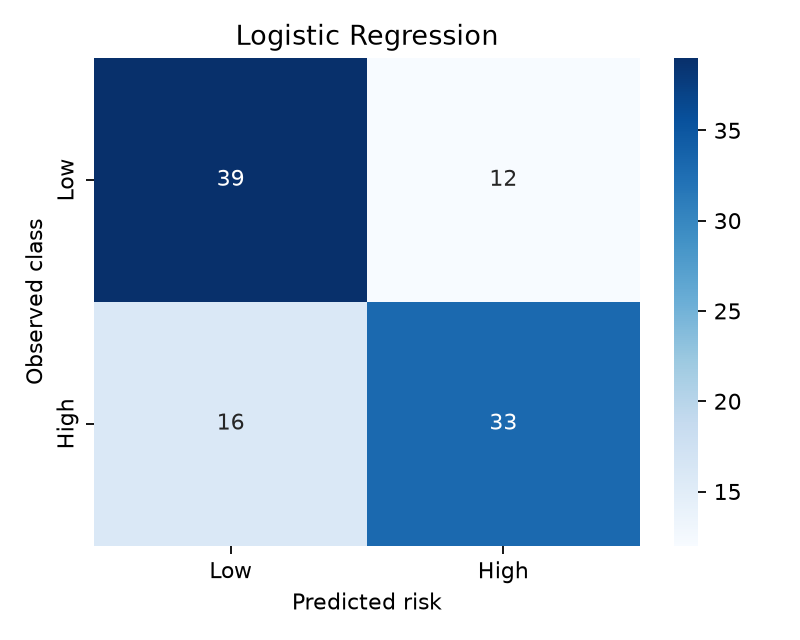

In [6]:
import pandas as pd
metrics = read_json(OUTPUT / 'figures/model_metrics.json')
display(pd.DataFrame({name: {'F1': m['f1'], 'AUC': m['auc']} for name,m in metrics['models'].items()}).T)
print('Selected:', metrics['selected'])
display(Image(filename=str(OUTPUT / 'figures' / (metrics['selected'] + '_confusion_matrix.png'))))